# Rolling Engle–Granger selection with continuous Kalman trading — zero costs

For every six-month trading window, select pairs using only its preceding 18 months. Preserve the established industry grouping, return correlation > 0.8, and Engle–Granger at 1%: test both directions and retain the qualifying direction with the lowest EG p-value. There is no multi-window pass requirement, Johansen test, or monthly eligibility gate. A window with no selected pairs holds cash.

Initialize alpha and beta once from the entire formation period, then carry the Kalman state and uncertainty forward through trading. Score each close before updating with that observation. Keep the formation spread standard deviation fixed, so the experiment changes alpha and beta rather than introducing a different z-score normalization. Estimate shared q and r using only that window's selected pairs' formation observations, and freeze them within the trading window.

Run only inside the established training partition: January 2015 through August 24, 2023. Trading starts after the first 18-month formation period, in July 2016. Retain the 18/6-month schedule, entry 1.5, exit 0.5, stop 4, equal allocation, next-close execution, fixed share quantities until exit, six-month stop resets, scheduled final-close liquidation, and zero costs. Reinitialize at each new trading window. The final formation close can signal an order for the first trading close.

The inherited filtered universe may contain survivorship or coverage bias. These are training-set research results, not out-of-sample validation. This notebook does not load prices on or after HOLDOUT_START.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from joint_grid_search import (DATA_START, HOLDOUT_START, COMMON_START,
    make_windows, screen_correlations, read_training_series, combine_accounts,
    performance_metrics, TRADE_COLUMNS, fit_direction, GridSearch)
# Refresh local code when this kernel previously loaded an older version.
import importlib
import kalman_backtest
importlib.reload(kalman_backtest)
from kalman_backtest import estimate_noise, backtest_kalman_pair, continuous_signals
from risk_free import load_treasury_yields

RUN_ID = None
base = ROOT / 'outputs/joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
expected = dict(formation_months=18, trading_months=6, correlation_threshold=.8,
                eg_significance=.01, entry_z=1.5, exit_z=.5, stop_z=4.)
matches = []
for path in run.glob('*/parameters.json'):
    candidate = json.loads(path.read_text())
    if all(candidate.get(k) == v for k, v in expected.items()) and candidate['cost_bps_per_leg'] == 0:
        matches.append((path.parent, candidate))
if len(matches) != 1:
    raise ValueError(f'Expected exactly one saved 18/6, .8/.01, 1.5/.5/4 zero-cost set; found {len(matches)}')
folder, params = matches[0]
initial = float(params['initial_capital'])
thresholds = {k: params[k] for k in ['entry_z', 'exit_z', 'stop_z']}
calendar = mcal.get_calendar('NYSE').valid_days(DATA_START, HOLDOUT_START-pd.Timedelta(days=1)).tz_localize(None)
dates = calendar[calendar >= COMMON_START]
assert dates.max() < HOLDOUT_START
print('Parameters:', params)
print('Training data:', calendar.min(), 'through', calendar.max())
print('Training-set trading:', dates.min(), 'through', dates.max())

Parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}
Training data: 2015-01-02 00:00:00 through 2023-08-24 00:00:00
Training-set trading: 2016-07-01 00:00:00 through 2023-08-24 00:00:00


## Rolling formation data

Selection slices exclude all trading-window observations. Missing formation history fails the existing screen.

In [2]:
# Keep the inherited filtered universe, but load dates needed by rolling formation.
universe = sorted(p.stem for p in (ROOT / 'data/Filter_historical').glob('*.csv'))
def load_bars(ticker):
    frame = pd.read_csv(ROOT / 'data/historical' / f'{ticker}.csv', usecols=['Date', 'Adj Close'])
    frame['Date'] = pd.to_datetime(frame['Date'])
    frame = frame.loc[frame['Date'].ge(DATA_START) & frame['Date'].lt(HOLDOUT_START)].set_index('Date').sort_index()
    if not frame.index.is_unique:
        raise ValueError(f'Duplicate dates: {ticker}')
    return pd.to_numeric(frame['Adj Close'], errors='coerce').rename(ticker)
prices = pd.concat([load_bars(t) for t in universe], axis=1).reindex(calendar)
mapping = pd.read_csv(ROOT / 'data/gics/ticker_gics.csv', dtype='string')
mapping['Ticker'] = mapping['Ticker'].str.strip().str.upper()
mapping['Industry Group Code'] = mapping['Industry Group Code'].str.strip()
if mapping['Ticker'].duplicated().any():
    raise ValueError('Duplicate universe tickers')
mapping = mapping.loc[mapping['Industry Group Code'].str.fullmatch(r'\d{4}', na=False) & mapping['Ticker'].isin(prices.columns)]
windows = make_windows(DATA_START, HOLDOUT_START, 18, 6, first_trading_start=COMMON_START)
assert windows['Trading End Exclusive'].le(HOLDOUT_START).all()


## Continuous Kalman trading

Each new trading window starts a fresh filter. No state is reset during that window; no future observations or smoothing enter signals.

Window 1: 23 pairs; final capital $100,059.17
Window 2: 7 pairs; final capital $100,065.28
Window 3: 5 pairs; final capital $100,070.01
Window 4: 6 pairs; final capital $100,542.37
Window 5: 9 pairs; final capital $100,443.05
Window 6: 5 pairs; final capital $100,311.63
Window 7: 11 pairs; final capital $100,462.62
Window 8: 3 pairs; final capital $104,875.82
Window 9: 24 pairs; final capital $104,721.77
Window 10: 18 pairs; final capital $104,625.55
Window 11: 28 pairs; final capital $104,643.93
Window 12: 9 pairs; final capital $105,146.76
Window 13: 6 pairs; final capital $105,096.84
Window 14: 9 pairs; final capital $104,724.74
Window 15: 8 pairs; final capital $104,771.35


,Window,Formation Start,Formation End Exclusive,Trading Start,Trading End Exclusive,Shortened,Selected Pairs,Initial Capital,Final Capital,q,r,Calibration
0,1,2015-01-01,2016-07-01,2016-07-01,2017-01-01,False,23,100000.000000,100059.171634,0.000004,1.075243e-05,"{""negative_log_likelihood"": -24901.03492857546..."
1,2,2015-07-01,2017-01-01,2017-01-01,2017-07-01,False,7,100059.171634,100065.282171,0.000003,1.947489e-06,"{""negative_log_likelihood"": -8001.666923087228..."
2,3,2016-01-01,2017-07-01,2017-07-01,2018-01-01,False,5,100065.282171,100070.006291,0.000004,8.661276e-06,"{""negative_log_likelihood"": -5301.040417024655..."
3,4,2016-07-01,2018-01-01,2018-01-01,2018-07-01,False,6,100070.006291,100542.373742,0.000002,1.181248e-05,"{""negative_log_likelihood"": -6620.617309527181..."
4,5,2017-01-01,2018-07-01,2018-07-01,2019-01-01,False,9,100542.373742,100443.051194,0.000002,4.072385e-06,"{""negative_log_likelihood"": -10567.77159284408..."
5,6,2017-07-01,2019-01-01,2019-01-01,2019-07-01,False,5,100443.051194,100311.629511,0.000004,1.914664e-06,"{""negative_log_likelihood"": -5650.348038772965..."
6,7,2018-01-01,2019-07-01,2019-07-01,2020-01-01,False,11,100311.629511,100462.621437,0.000002,3.651488e-06,"{""negative_log_likelihood"": -12675.01939015241..."
7,8,2018-07-01,2020-01-01,2020-01-01,2020-07-01,False,3,100462.621437,104875.823385,0.000002,1.134299e-06,"{""negative_log_likelihood"": -3519.302767000811..."
8,9,2019-01-01,2020-07-01,2020-07-01,2021-01-01,False,24,104875.823385,104721.766566,0.000024,8.141402e-05,"{""negative_log_likelihood"": -17595.96551210823..."
9,10,2019-07-01,2021-01-01,2021-01-01,2021-07-01,False,18,104721.766566,104625.550822,0.000018,6.983196e-05,"{""negative_log_likelihood"": -14019.86261960457..."


,Rolling EG / continuous Kalman
Cumulative Return,0.047713
Gross Cumulative Return,0.047713
Annualized Return,0.006550
Annualized Volatility,0.010250
Annualized Risk-Free Return,0.015266
Sharpe Ratio,-0.850246
Maximum Drawdown,0.007319
Number of Trades,141.000000
Win Rate,0.574468
Average P/L per Trade ($),33.839339


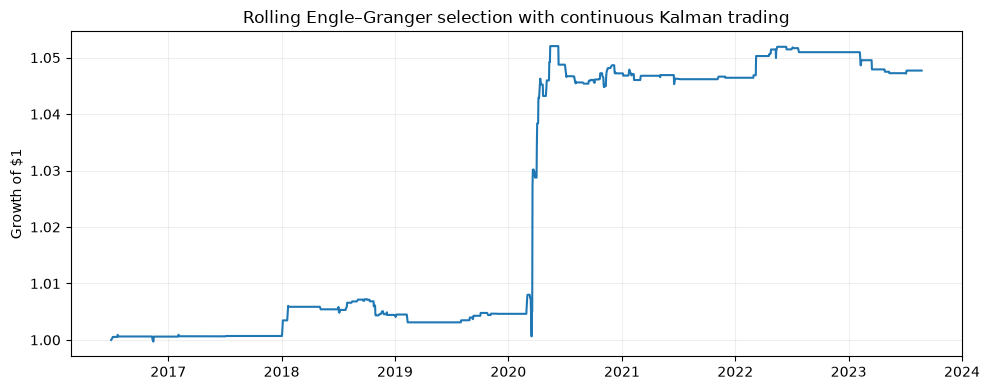

In [3]:
capital = initial
screen_parts, selected_parts, signal_parts = [], [], []
daily_parts, trade_parts, pair_daily_parts, window_rows = [], [], [], []
for _, window in windows.iterrows():
    number = int(window['Window'])
    formation = prices.loc[(prices.index >= window['Formation Start']) & (prices.index < window['Trading Start'])]
    block_dates = dates[(dates >= window['Trading Start']) & (dates < window['Trading End Exclusive'])]
    if block_dates.empty:
        continue
    assert formation.index.max() < block_dates.min()
    comparisons, _ = screen_correlations(formation, mapping, params['correlation_threshold'])
    fits = []
    for _, pair in comparisons.iterrows():
        if not pair['Screen Passed']:
            continue
        a, b = pair['Ticker 1'], pair['Ticker 2']
        for dependent, independent in [(a, b), (b, a)]:
            row = pair.to_dict() | {'A': dependent, 'B': independent}
            try:
                row.update(fit_direction(np.log(formation[[dependent, independent]]), dependent, independent))
            except (ValueError, np.linalg.LinAlgError, Warning) as error:
                row['Status'] = str(error)
            fits.append(row)
    fit_columns = list(comparisons.columns) + ['A', 'B', 'Alpha', 'Beta', 'Spread Mean', 'Spread Std',
                                               'EG Statistic', 'EG p-value', 'EG 1% Critical Value', 'EG 5% Critical Value']
    directions = pd.DataFrame(fits).reindex(columns=list(dict.fromkeys(fit_columns)))
    selected = GridSearch.select(directions, params['correlation_threshold'], params['eg_significance'])
    screen_parts.append(comparisons.assign(Window=number))
    selected_parts.append(selected.assign(Window=number))
    accounts, block_trades = [], []
    q = r = None
    calibration = None
    if not selected.empty:
        q, r, calibration = estimate_noise([np.log(formation[[p.A, p.B]]) for _, p in selected.iterrows()])
    for _, pair in selected.iterrows():
        bars = prices.loc[block_dates, [pair.A, pair.B]]
        if not (np.isfinite(bars) & bars.gt(0)).all().all():
            raise ValueError(f'Invalid trading prices: {pair.A}/{pair.B}; selected pair was not dropped')
        signal = continuous_signals(formation[[pair.A, pair.B]], bars, q, r)
        daily, result = backtest_kalman_pair(pair, bars, signal, formation.iloc[-1],
            capital / len(selected), params['cost_bps_per_leg'], **thresholds)
        accounts.append(daily)
        block_trades.append(result.assign(Window=number))
        signal_parts.append(signal.assign(Window=number, A=pair.A, B=pair.B))
        pair_daily_parts.append(daily.assign(Window=number, A=pair.A, B=pair.B))
    combined = combine_accounts(accounts, block_dates, capital)
    result = pd.concat(block_trades, ignore_index=True) if block_trades else pd.DataFrame(columns=[*TRADE_COLUMNS, 'Entry Beta', 'Window'])
    np.testing.assert_allclose(combined['Equity'].iloc[-1] - capital, result['Net P/L ($)'].sum(), atol=1e-6)
    window_rows.append({**window.to_dict(), 'Selected Pairs': len(selected), 'Initial Capital': capital,
                        'Final Capital': combined['Equity'].iloc[-1], 'q': q, 'r': r,
                        'Calibration': json.dumps(calibration)})
    capital = float(combined['Equity'].iloc[-1])
    daily_parts.append(combined.assign(Window=number))
    trade_parts.append(result)
    print(f'Window {number}: {len(selected)} pairs; final capital ${capital:,.2f}')
portfolio = pd.concat(daily_parts)
trades = pd.concat(trade_parts, ignore_index=True)
assert portfolio.index.equals(dates)
np.testing.assert_allclose(initial * (1 + portfolio['Net Return']).cumprod(), portfolio['Equity'], rtol=1e-9)
np.testing.assert_allclose(capital - initial, trades['Net P/L ($)'].sum(), atol=1e-6)
assert (pd.to_datetime(trades['Entry Signal Date']) < pd.to_datetime(trades['Entry Date'])).all()
# Pick up a refreshed snapshot even when the kernel cached older yields.
load_treasury_yields.cache_clear()
yields = load_treasury_yields(ROOT / 'data/risk_free/DGS3MO.csv')
metrics = pd.Series(performance_metrics(portfolio, trades, initial, yields), name='Rolling EG / continuous Kalman')
display(pd.DataFrame(window_rows))
display(metrics.to_frame())
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(portfolio.index, portfolio['Equity'] / initial)
ax.set(title='Rolling Engle–Granger selection with continuous Kalman trading', ylabel='Growth of $1')
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


## Save experiment audits

In [4]:
out = ROOT / 'outputs/kalman_rolling_eg_training_zero_cost' / run.name / folder.name
out.mkdir(parents=True, exist_ok=True)
pd.concat(screen_parts).to_csv(out / 'screening_window_tests.csv', index=False)
pd.concat(selected_parts).to_csv(out / 'selected_pairs.csv', index=False)
pd.DataFrame(window_rows).to_csv(out / 'window_summary.csv', index=False)
portfolio.to_csv(out / 'portfolio_daily.csv')
trades.to_csv(out / 'trades.csv', index=False)
metrics.to_csv(out / 'performance_metrics.csv')
if signal_parts:
    pd.concat(signal_parts).to_csv(out / 'kalman_signals.csv.gz', compression='gzip')
    pd.concat(pair_daily_parts).to_csv(out / 'pair_daily.csv.gz', compression='gzip')
fig.savefig(out / 'portfolio.png', dpi=160, bbox_inches='tight')
(out / 'experiment_manifest.json').write_text(json.dumps({
    'source_run': run.name, 'parameters': params,
    'selection': 'Rolling 18-month formation; existing bidirectional EG selection; reselect every six months',
    'kalman': 'Full-formation OLS initialization, continuous trading updates, no daily refit',
    'z_scale': 'Fixed formation residual sample standard deviation',
    'noise': 'Pooled formation-only likelihood per window; frozen during trading',
    'execution': 'Previous-close signal; next-close fill; fixed units until exit; final-close liquidation',
    'partition': 'training',
    'data_start': str(calendar.min()), 'trading_start': str(dates.min()),
    'trading_end': str(dates.max()), 'end_exclusive': str(HOLDOUT_START),
    'holdout_loaded': False,
}, indent=2))
print('Saved:', out.relative_to(ROOT))


Saved: outputs/kalman_rolling_eg_training_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4
